In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image, UnidentifiedImageError
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

print(" Libraries imported successfully!")

 Libraries imported successfully!


In [30]:
import os

# load dataset path
original_dir = "/content/drive/MyDrive/workshop5/Flower Classification/Train"
base_dir     = "/content/drive/MyDrive/workshop5/split_data"
train_dir    = os.path.join(base_dir, "train")
val_dir      = os.path.join(base_dir, "val")
test_dir     = os.path.join(base_dir, "test")

#
IMG_SIZE   = (128, 128)
BATCH_SIZE = 32

In [31]:
classes = os.listdir(original_dir)

print("Classes:", classes)
print("Number of classes:", len(classes))

Classes: ['daisy', 'rose', 'tulip', 'dandelion', 'sunflower']
Number of classes: 5


In [32]:
total_images = 0
class_counts = {}

for cls in classes:
    class_path = os.path.join(original_dir, cls)
    if os.path.isdir(class_path): # Check if it's a directory
        total_images += len(os.listdir(class_path))
        class_counts[cls] = len(os.listdir(class_path))


print("Total images in dataset:", total_images)
print(class_counts)

Total images in dataset: 4292
{'daisy': 756, 'rose': 776, 'tulip': 991, 'dandelion': 1044, 'sunflower': 725}


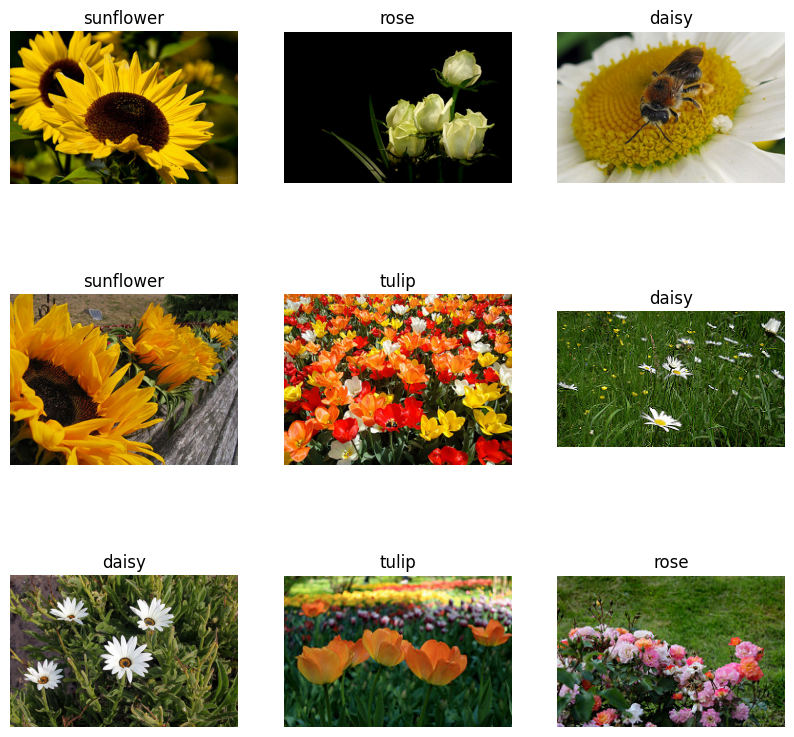

In [36]:
import os # For os.path.join, os.listdir
import random # For random.choice
import matplotlib.pyplot as plt # For plt.figure, plt.subplot, plt.imshow, plt.title, plt.axis, plt.show
from PIL import Image # For Image.open

#Show sample images

plt.figure(figsize=(10,10))

for i in range(9):
    cls = random.choice(classes)
    img_path = os.path.join(original_dir, cls, random.choice(os.listdir(os.path.join(original_dir, cls))))

    img = Image.open(img_path)

    plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis('off')

plt.show()

#Check for Corrupted Images

In [37]:
#check for the corrupted images
corrupted_images = []  # List to store corrupted image paths

for class_name in classes:
    class_path = os.path.join(original_dir, class_name)
    if os.path.isdir(class_path):
        images = os.listdir(class_path)
        for img_name in images:
            img_path = os.path.join(class_path, img_name)
            try:
                with Image.open(img_path) as img:
                    img.verify()  # Verify image integrity
            except (IOError, UnidentifiedImageError):
                corrupted_images.append(img_path)

# Print results
if corrupted_images:
    print(f"\n  Corrupted Images Found: {len(corrupted_images)}")
    for img in corrupted_images:
        print(f"   Removing: {img}")
        os.remove(img)
    print(" Corrupted images removed.")
else:
    print("\n No corrupted images found.")


 No corrupted images found.


#Check Class Balance

###A balanced dataset ensures no class dominates the model. If some classes have significantly more images, the model become biased towards those classes.

In [38]:
# Dictionary to store class counts
class_counts = {}

for class_name in classes:
    class_path = os.path.join(original_dir, class_name)
    if os.path.isdir(class_path):
        images = [img for img in os.listdir(class_path)
                  if img.lower().endswith(('.png', '.jpg', '.jpeg'))]
        class_counts[class_name] = len(images)

# Print Class Distribution
total = sum(class_counts.values())

print("\nClass Distribution:")
print("=" * 55)
print(f"{'Class Name':<20} {'Image Count':>12} {'Percentage':>12}")
print("=" * 55)
for class_name, count in class_counts.items():
    pct = (count / total) * 100
    print(f"{class_name:<20} {count:>12} {pct:>11.1f}%")
print("=" * 55)
print(f"{'TOTAL':<20} {total:>12} {'100.0%':>12}")


Class Distribution:
Class Name            Image Count   Percentage
daisy                         756        17.6%
rose                          776        18.1%
tulip                         991        23.1%
dandelion                    1044        24.3%
sunflower                     725        16.9%
TOTAL                        4292       100.0%


As you can see, in my dataset, there is no severe imbalance so it doesnot require correction.

#Visualize Class Distribution

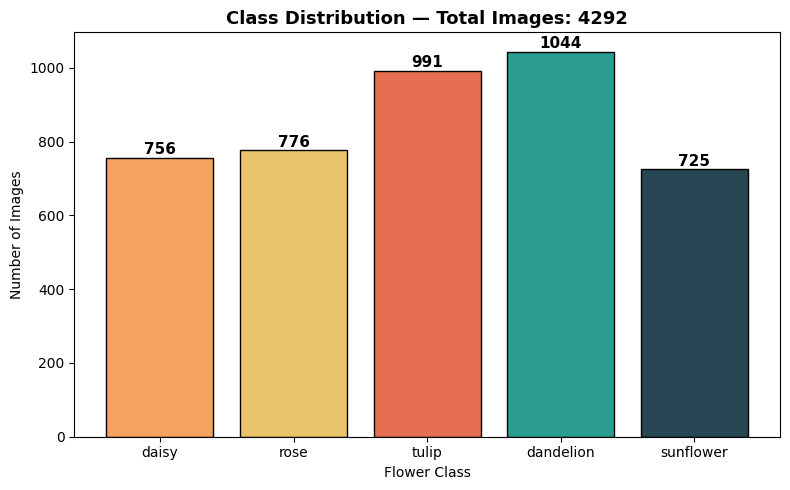

In [39]:
colors = ["#f4a261", "#e9c46a", "#e76f51", "#2a9d8f", "#264653"]
plt.figure(figsize=(8, 5))
bars = plt.bar(class_counts.keys(), class_counts.values(),
               color=colors, edgecolor='black')

for bar, count in zip(bars, class_counts.values()):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 10,
             str(count), ha='center', fontsize=11, fontweight='bold')

plt.title(f"Class Distribution — Total Images: {total}", fontsize=13, fontweight='bold')
plt.xlabel("Flower Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

##Sample images of each classes

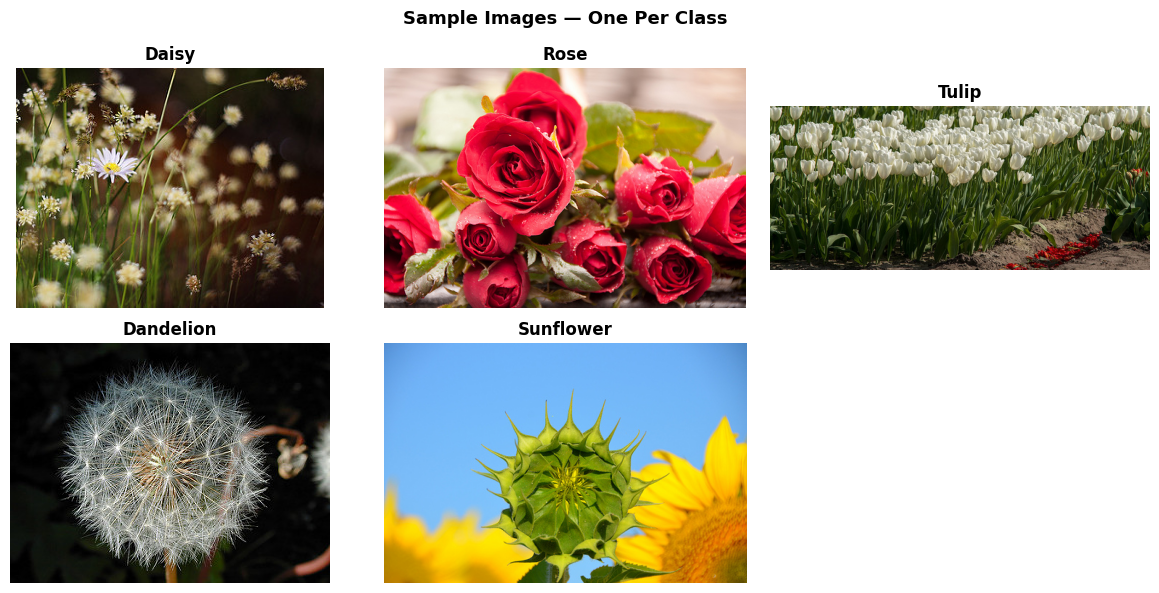

In [40]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

selected_images = []  # Store image paths
selected_labels = []  # Store corresponding class names

for class_name in classes:
    class_path = os.path.join(original_dir, class_name)
    if os.path.isdir(class_path):
        images = [img for img in os.listdir(class_path)
                  if img.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if images:
            selected_img = os.path.join(class_path, random.choice(images))
            selected_images.append(selected_img)
            selected_labels.append(class_name)

# Plot in grid
num_classes = len(selected_images)
cols = (num_classes + 1) // 2
rows = 2

fig, axes = plt.subplots(rows, cols, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i < num_classes:
        img = mpimg.imread(selected_images[i])
        ax.imshow(img)
        ax.set_title(selected_labels[i].capitalize(), fontweight='bold')
        ax.axis("off")
    else:
        ax.axis("off")  # Hide empty subplots

plt.suptitle("Sample Images — One Per Class", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

##Split Dataset - Trian, Validation adn Test

In [41]:
import os
import shutil
import random

# Force a clean split every time this cell is run.
# If base_dir exists, remove it and its contents.
if os.path.exists(base_dir):
    print(" Removing existing split directory to perform a clean split...")
    shutil.rmtree(base_dir)

print("Creating split folders...")

# Create base directory and subdirectories for train, val, test
os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# Iterate through each original class folder
for cls in classes: # Use 'classes' (globally defined) instead of 'class_names' (defined after split)
    cls_path = os.path.join(original_dir, cls)
    if os.path.isdir(cls_path):
        images = [f for f in os.listdir(cls_path)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        random.shuffle(images)

        total_cls  = len(images)
        train_end  = int(0.70 * total_cls)
        val_end    = int(0.85 * total_cls)

        for i, img in enumerate(images):
            src = os.path.join(cls_path, img)
            if i < train_end:
                dst_dir = os.path.join(train_dir, cls)
            elif i < val_end:
                dst_dir = os.path.join(val_dir, cls)
            else:
                dst_dir = os.path.join(test_dir, cls)

            os.makedirs(dst_dir, exist_ok=True)
            shutil.copy(src, os.path.join(dst_dir, img))

print(" Dataset split complete!")

# ── Print split summary ──
print("\nSplit Summary:")
print("=" * 40)
print(f"{'Split':<15} {'Images':>10} {'%':>8}")
print("=" * 40)

# Recalculate total from original_dir to get correct percentages
# Use the 'class_counts' dictionary that was populated earlier for the original_dir
total_original_images = sum(class_counts.values())

for split_name, split_dir in [("Train", train_dir), ("Validation", val_dir), ("Test", test_dir)]:
    count = 0
    if os.path.exists(split_dir):
        for cls_sub_dir in os.listdir(split_dir):
            full_cls_path = os.path.join(split_dir, cls_sub_dir)
            if os.path.isdir(full_cls_path):
                count += len(os.listdir(full_cls_path))

    # Only calculate percentage if total_original_images is not zero to avoid division by zero
    pct = (count / total_original_images * 100) if total_original_images > 0 else 0.0
    print(f"{split_name:<15} {count:>10}  {pct:>6.1f}%")
print("=" * 40)

 Removing existing split directory to perform a clean split...
Creating split folders...
 Dataset split complete!

Split Summary:
Split               Images        %
Train                 3002    69.9%
Validation             644    15.0%
Test                   646    15.1%


In [42]:
# ── Only split if not already done ──
if os.path.exists(base_dir) and len(os.listdir(base_dir)) > 0:
    print(" Split already exists — skipping to avoid duplicates.")
else:
    print(" Creating split folders...")

    for folder in [train_dir, val_dir, test_dir]:
        os.makedirs(folder, exist_ok=True)

    for cls in classes:
        cls_path = os.path.join(original_dir, cls)
        if os.path.isdir(cls_path):
            images = [f for f in os.listdir(cls_path)
                      if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            random.shuffle(images)

            total_cls  = len(images)
            train_end  = int(0.70 * total_cls)
            val_end    = int(0.85 * total_cls)

            for i, img in enumerate(images):
                src = os.path.join(cls_path, img)
                if i < train_end:
                    dst_dir = os.path.join(train_dir, cls)
                elif i < val_end:
                    dst_dir = os.path.join(val_dir, cls)
                else:
                    dst_dir = os.path.join(test_dir, cls)

                os.makedirs(dst_dir, exist_ok=True)
                shutil.copy(src, os.path.join(dst_dir, img))

    print(" Dataset split complete!")

# ── Print split summary ──
print("\nSplit Summary:")
print("=" * 40)
print(f"{'Split':<15} {'Images':>10} {'%':>8}")
print("=" * 40)
for split_name, split_dir in [("Train", train_dir), ("Validation", val_dir), ("Test", test_dir)]:
    count = sum(
        len(os.listdir(os.path.join(split_dir, cls)))
        for cls in os.listdir(split_dir)
        if os.path.isdir(os.path.join(split_dir, cls))
    )
    print(f"{split_name:<15} {count:>10}  {count/total*100:>6.1f}%")
print("=" * 40)

 Split already exists — skipping to avoid duplicates.

Split Summary:
Split               Images        %
Train                 3002    69.9%
Validation             644    15.0%
Test                   646    15.1%


##Check Class Imbalance After Split

In [43]:
# Update class_names from train_dir after split
class_names = sorted(os.listdir(train_dir))

# Count per class in train
class_counts_train = {}
for class_name in class_names:
    class_path = os.path.join(train_dir, class_name)
    if os.path.isdir(class_path):
        images = [img for img in os.listdir(class_path)
                  if img.lower().endswith(('.png', '.jpg', '.jpeg'))]
        class_counts_train[class_name] = len(images)

train_total = sum(class_counts_train.values())

print("\nClass Distribution (Train Set):")
print("=" * 45)
print(f"{'Class Name':<25}{'Valid Image Count':>15}")
print("=" * 45)
for class_name, count in class_counts_train.items():
    print(f"{class_name:<25}{count:>15}")
print("=" * 45)


Class Distribution (Train Set):
Class Name               Valid Image Count
daisy                                529
dandelion                            730
rose                                 543
sunflower                            507
tulip                                693


##Data Augmentatioin

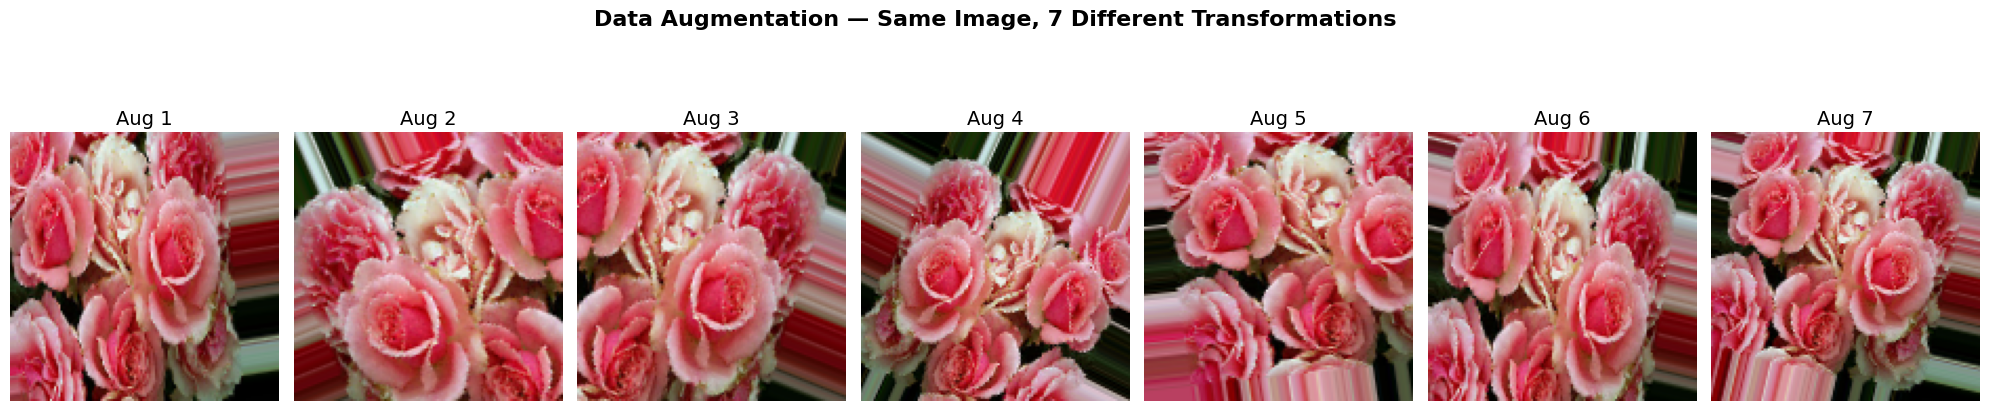

In [44]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import numpy as np

datagen = ImageDataGenerator(
    rotation_range=30,       # Rotate images by up to 30 degrees
    width_shift_range=0.2,   # Shift width by 20%
    height_shift_range=0.2,  # Shift height by 20%
    shear_range=0.2,         # Shear transformation
    zoom_range=0.2,          # Zoom in/out by 20%
    horizontal_flip=True,    # Flip images horizontally
    fill_mode='nearest'      # Fill in missing pixels
)

# Load one sample image from train/rose
rose_dir        = os.path.join(train_dir, "rose")
sample_img_name = random.choice(os.listdir(rose_dir))
sample_img_path = os.path.join(rose_dir, sample_img_name)

img = image.load_img(sample_img_path, target_size=IMG_SIZE)
x   = image.img_to_array(img)
x   = np.expand_dims(x, axis=0)

# Generate and visualize 7 augmented images
aug_iter = datagen.flow(x, batch_size=1)

fig, axes = plt.subplots(1, 7, figsize=(20, 5))
fig.suptitle("Data Augmentation — Same Image, 7 Different Transformations",
             fontsize=16, fontweight='bold')

for i in range(7):
    batch = next(aug_iter)
    axes[i].imshow(batch[0].astype('uint8'))
    axes[i].set_title(f"Aug {i+1}", fontsize=14)
    axes[i].axis('off')

plt.tight_layout()
plt.show()


##Create ImageDataGenerator for Training

In [45]:
# ── Training Generator: Augmentation + Normalization ──
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# ── Val & Test Generators: Normalization ONLY ──
val_datagen  = ImageDataGenerator(rescale=1.0 / 255)
test_datagen = ImageDataGenerator(rescale=1.0 / 255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"\nClass indices : {train_generator.class_indices}")
print(f"   Train batches : {len(train_generator)}")
print(f"   Val   batches : {len(val_generator)}")
print(f"   Test  batches : {len(test_generator)}")

Found 3002 images belonging to 5 classes.
Found 644 images belonging to 5 classes.
Found 646 images belonging to 5 classes.

Class indices : {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}
   Train batches : 94
   Val   batches : 21
   Test  batches : 21


#Build the baseline CNN model

The baseline model follows this structure:
- **3 × Convolutional layers** — each followed by a MaxPooling layer
- **3 × Fully Connected (Dense) layers**
- **1 × Output layer** with softmax activation for 5-class classification

We use **ReLU** activation for all hidden layers as it is computationally efficient and avoids the vanishing gradient problem.

In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Activation, Dropout

NUM_CLASSES = len(class_names)

# ── Baseline CNN Model ──
baseline_model = Sequential([

    # ── Convolutional Block 1 ──
    # 32 filters, 3x3 kernel, ReLU activation
    Conv2D(32, (3, 3), activation='relu', padding='same',
           input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    # ── Convolutional Block 2 ──
    # 64 filters — more filters to learn more complex features
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # ── Convolutional Block 3 ──
    # 128 filters — deeper features
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # ── Flatten ──
    # Convert 3D feature maps to 1D vector
    Flatten(),

    # ── Fully Connected Layers ──
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64,  activation='relu'),

    # ── Output Layer ──
    # 5 neurons = 5 flower classes, softmax for probability distribution
    Dense(NUM_CLASSES, activation='softmax')
])

print(" Baseline model built successfully!")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


 Baseline model built successfully!


In [47]:
#Model Summary

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,523,589 (32.51 MB)

 Trainable params: 8,523,589 (32.51 MB)

 Non-trainable params: 0 (0.00 B)

##Compiling the Baseline Model

In [48]:
baseline_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(" Model compiled successfully!")

 Model compiled successfully!


##Train the Model

###We use the Earlystopping to prent from the overfitting and saves training time.

In [49]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if val_loss does not improve for 5 consecutive epochs
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

import time
start_time = time.time()

baseline_history = baseline_model.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator,
    callbacks=[early_stopping]
)

baseline_training_time = time.time() - start_time
print(f"\nTraining time: {baseline_training_time:.2f} seconds")

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 48s 437ms/step - accuracy: 0.4157 - loss: 1.3313 - val_accuracy: 0.4550 - val_loss: 1.2937
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 318ms/step - accuracy: 0.5233 - loss: 1.1332 - val_accuracy: 0.5248 - val_loss: 1.1375
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 316ms/step - accuracy: 0.5720 - loss: 1.0493 - val_accuracy: 0.5807 - val_loss: 1.0314
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 315ms/step - accuracy: 0.6169 - loss: 0.9591 - val_accuracy: 0.6382 - val_loss: 0.9566
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 314ms/step - accuracy: 0.6342 - loss: 0.9279 - val_accuracy: 0.6118 - val_loss: 0.9636
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 312ms/step - accuracy: 0.6572 - loss: 0.8786 - val_accuracy: 0.6568 - val_loss: 0.8587
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 314ms/step - accuracy: 0.6582 - loss: 0.8645 - val_accuracy: 0.6879 - val_loss: 0.8355
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 311ms/step - accuracy: 0.6679 - loss: 0.8454 - val_accu

##Plot Traiing vs Validation Loss and Accuracy

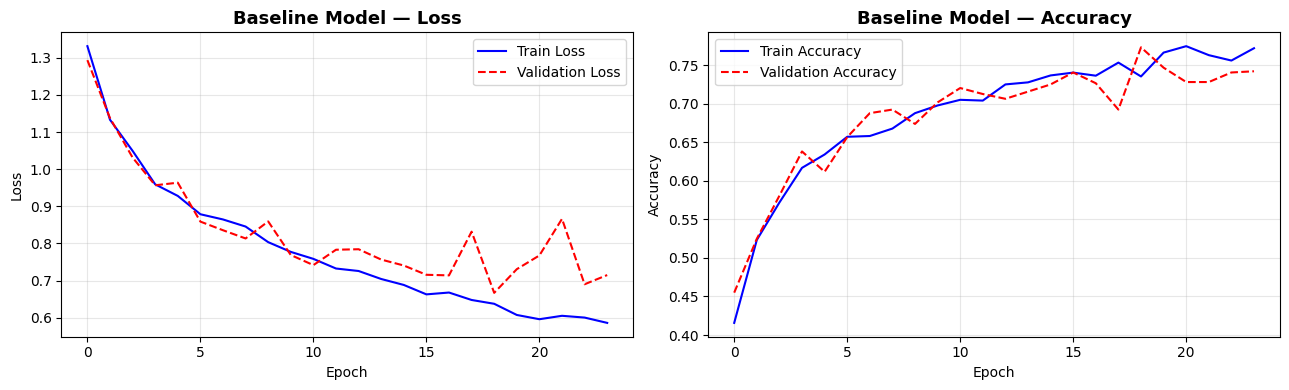

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# ── Loss ──
axes[0].plot(baseline_history.history['loss'],     label='Train Loss',      color='blue')
axes[0].plot(baseline_history.history['val_loss'], label='Validation Loss', color='red', linestyle='--')
axes[0].set_title('Baseline Model — Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# ── Accuracy ──
axes[1].plot(baseline_history.history['accuracy'],     label='Train Accuracy',      color='blue')
axes[1].plot(baseline_history.history['val_accuracy'], label='Validation Accuracy', color='red', linestyle='--')
axes[1].set_title('Baseline Model — Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("baseline_training_curves.png", dpi=150, bbox_inches='tight')
plt.show()


##Evaluate the Model in the Test Set

In [51]:
test_loss, test_accuracy = baseline_model.evaluate(test_generator)

print("\n" + "=" * 40)
print(f"  Baseline Model — Test Results")
print("=" * 40)
print(f"  Test Loss     : {test_loss:.4f}")
print(f"  Test Accuracy : {test_accuracy * 100:.2f}%")
print("=" * 40)

21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 167ms/step - accuracy: 0.7570 - loss: 0.6748

  Baseline Model — Test Results
  Test Loss     : 0.6748
  Test Accuracy : 75.70%


In [52]:
from sklearn.metrics import classification_report

# Get true labels and predictions
test_generator.reset()
predictions    = baseline_model.predict(test_generator)
predicted_labels = np.argmax(predictions, axis=1)
true_labels      = test_generator.classes
class_names      = list(test_generator.class_indices.keys())

print("\nClassification Report:")
print("=" * 60)
print(classification_report(true_labels, predicted_labels,
                             target_names=class_names))

21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/step

Classification Report:
              precision    recall  f1-score   support

       daisy       0.75      0.78      0.77       114
   dandelion       0.79      0.84      0.81       157
        rose       0.66      0.69      0.68       117
   sunflower       0.81      0.80      0.81       109
       tulip       0.76      0.67      0.71       149

    accuracy                           0.76       646
   macro avg       0.76      0.76      0.76       646
weighted avg       0.76      0.76      0.76       646



#Confusion Matrix

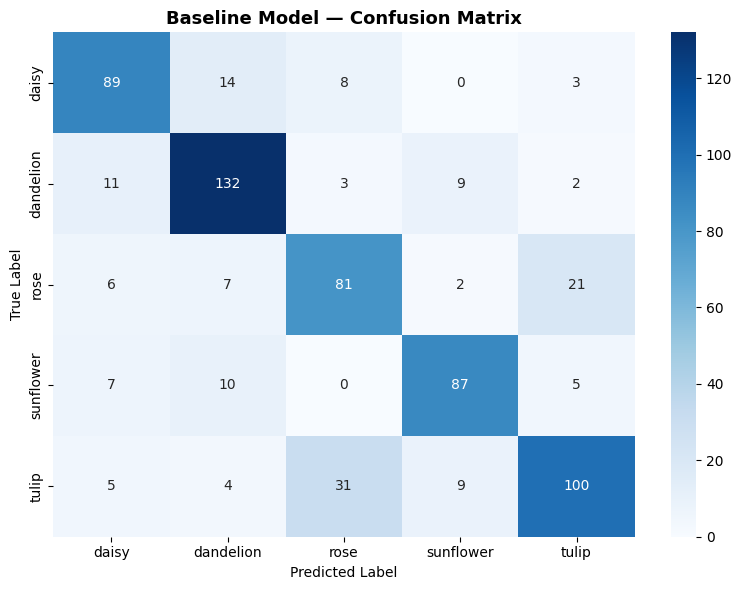

In [53]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Baseline Model — Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig("baseline_confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()


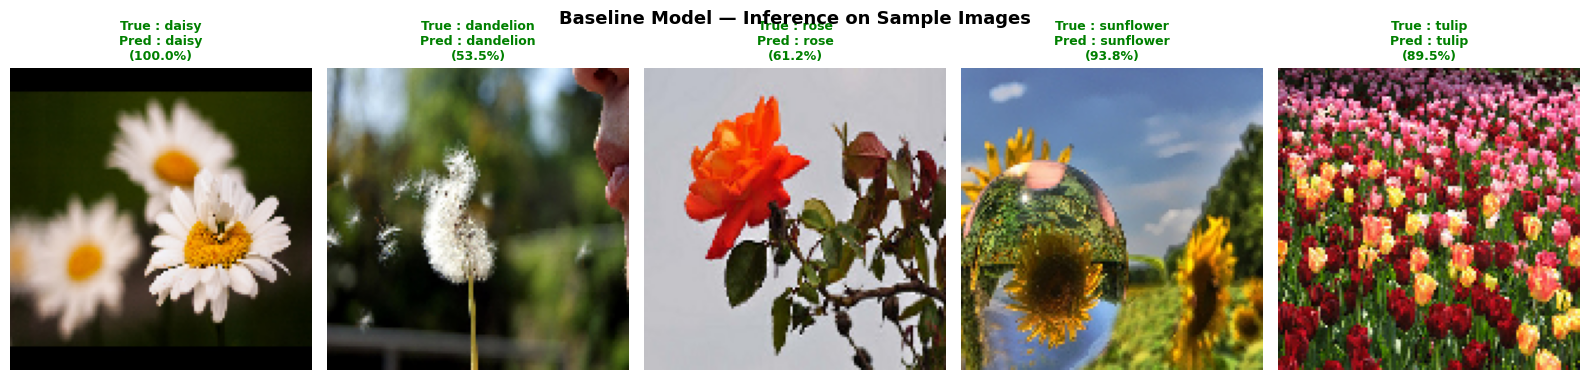


Green title = Correct prediction
   Red title   = Wrong prediction


In [54]:
import random
from tensorflow.keras.preprocessing import image as keras_image

# Pick 5 random images from test set
sample_images = []
sample_labels = []

for class_name in class_names:
    class_path = os.path.join(test_dir, class_name)
    images     = os.listdir(class_path)
    img_name   = random.choice(images)
    sample_images.append(os.path.join(class_path, img_name))
    sample_labels.append(class_name)

# Plot predictions
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
fig.suptitle("Baseline Model — Inference on Sample Images",
             fontsize=13, fontweight='bold')

for i, (img_path, true_label) in enumerate(zip(sample_images, sample_labels)):
    # Load and preprocess
    img      = keras_image.load_img(img_path, target_size=IMG_SIZE)
    img_arr  = keras_image.img_to_array(img) / 255.0
    img_arr  = np.expand_dims(img_arr, axis=0)

    # Predict
    pred        = baseline_model.predict(img_arr, verbose=0)
    pred_label  = class_names[np.argmax(pred)]
    confidence  = np.max(pred) * 100

    # Plot
    axes[i].imshow(keras_image.load_img(img_path, target_size=IMG_SIZE))
    axes[i].axis('off')

    color = 'green' if pred_label == true_label else 'red'
    axes[i].set_title(
        f"True : {true_label}\nPred : {pred_label}\n({confidence:.1f}%)",
        fontsize=9, color=color, fontweight='bold'
    )

plt.tight_layout()
plt.savefig("baseline_inference.png", dpi=150, bbox_inches='tight')
plt.show()
print("\nGreen title = Correct prediction")
print("   Red title   = Wrong prediction")

##Save the baseline model

In [55]:
baseline_model.save("baseline_model.h5")
print("Baseline model saved as baseline_model.h5")

Baseline model saved as baseline_model.h5


#Build the Deeper CNN Model

Compared to the baseline (3 conv layers), this model has **6 convolutional layers** — double the depth.

Two new techniques are added:

**BatchNormalization:**
- Normalizes the output of each layer during training
- Helps the model train faster and more stably
- Reduces sensitivity to weight initialization

**Dropout:**
- Randomly switches off a fraction of neurons during training
- Prevents the model from memorizing training data (overfitting)
- `Dropout(0.25)` = 25% of neurons are switched off per step

In [56]:
def build_deeper_model(optimizer):
    """
    Builds and compiles the deeper CNN model.
    optimizer: pass 'adam' or SGD() object
    """
    model = Sequential([

        # ── Conv Block 1 ── (32 filters)
        Conv2D(32, (3, 3), padding='same', input_shape=(128, 128, 3)),
        BatchNormalization(),
        Activation('relu'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # ── Conv Block 2 ── (64 filters)
        Conv2D(64, (3, 3), padding='same'),
        BatchNormalization(),
        Activation('relu'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # ── Conv Block 3 ── (128 filters)
        Conv2D(128, (3, 3), padding='same'),
        BatchNormalization(),
        Activation('relu'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # ── Conv Block 4 ── (256 filters)
        Conv2D(256, (3, 3), padding='same'),
        BatchNormalization(),
        Activation('relu'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # ── Conv Block 5 ── (512 filters)
        Conv2D(512, (3, 3), padding='same'),
        BatchNormalization(),
        Activation('relu'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # ── Conv Block 6 ── (512 filters)
        Conv2D(512, (3, 3), padding='same'),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.25),

        # ── Flatten ──
        Flatten(),

        # ── Fully Connected Layers ──
        Dense(512),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.5),

        Dense(256),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.5),

        Dense(128),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.5),

        # ── Output Layer ──
        Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print("build_deeper_model() function defined.")

build_deeper_model() function defined.


In [57]:
# Print summary using Adam (architecture is same regardless of optimizer)
temp_model = build_deeper_model('adam')
temp_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 8,297,669 (31.65 MB)

 Trainable params: 8,292,869 (31.63 MB)

 Non-trainable params: 4,800 (18.75 KB)

##Train the Deeper Model using Adam

In [58]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import time

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Build with Adam
model_adam = build_deeper_model(optimizer=Adam(learning_rate=0.001))

print("Training Deeper Model with ADAM...")
start_adam = time.time()

history_adam = model_adam.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator,
    callbacks=[early_stopping]
)

time_adam = time.time() - start_adam
print(f"\n Adam Training Time: {time_adam:.2f} seconds")

Training Deeper Model with ADAM...
Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 63s 472ms/step - accuracy: 0.3261 - loss: 1.7363 - val_accuracy: 0.2438 - val_loss: 2.8070
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 314ms/step - accuracy: 0.4071 - loss: 1.4489 - val_accuracy: 0.2438 - val_loss: 4.3404
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 317ms/step - accuracy: 0.4564 - loss: 1.3012 - val_accuracy: 0.2438 - val_loss: 4.5670
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 312ms/step - accuracy: 0.5040 - loss: 1.2082 - val_accuracy: 0.2484 - val_loss: 4.5048
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 32s 342ms/step - accuracy: 0.5630 - loss: 1.1086 - val_accuracy: 0.3416 - val_loss: 2.9003
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 312ms/step - accuracy: 0.5806 - loss: 1.0431 - val_accuracy: 0.3804 - val_loss: 2.4728
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 319ms/step - accuracy: 0.6013 - loss: 1.0171 - val_accuracy: 0.5031 - val_loss: 1.4090
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 322ms/step - accurac

##Adam Plot Trainign vs Vlidation Loss and Accuracy

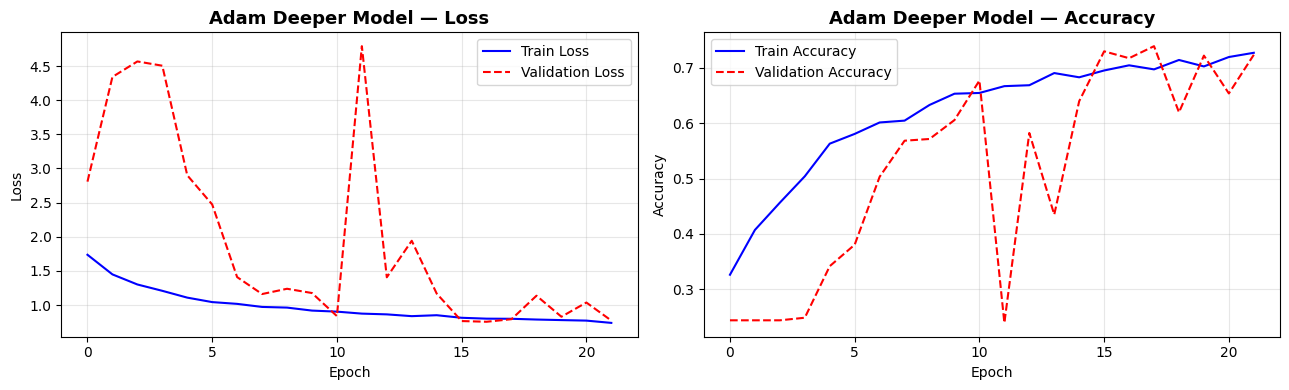

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss
axes[0].plot(history_adam.history['loss'],     label='Train Loss',      color='blue')
axes[0].plot(history_adam.history['val_loss'], label='Validation Loss', color='red', linestyle='--')
axes[0].set_title('Adam Deeper Model — Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history_adam.history['accuracy'],     label='Train Accuracy',      color='blue')
axes[1].plot(history_adam.history['val_accuracy'], label='Validation Accuracy', color='red', linestyle='--')
axes[1].set_title('Adam Deeper Model — Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("deeper_training_curves.png", dpi=150, bbox_inches='tight')
plt.show()


#Train Deeper Model with SGD Optimizer

In [60]:
from tensorflow.keras.optimizers import SGD

# Build with SG
model_sgd = build_deeper_model(
    optimizer=SGD(learning_rate=0.001, momentum=0.9)
)

print("Training Deeper Model with SGD...")
start_sgd = time.time()

history_sgd = model_sgd.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator,
    callbacks=[early_stopping]
)

time_sgd = time.time() - start_sgd
print(f"\n SGD Training Time: {time_sgd:.2f} seconds")

Training Deeper Model with SGD...
Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 56s 440ms/step - accuracy: 0.2522 - loss: 1.9737 - val_accuracy: 0.2438 - val_loss: 2.0239
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 307ms/step - accuracy: 0.3511 - loss: 1.5770 - val_accuracy: 0.2438 - val_loss: 2.4503
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 306ms/step - accuracy: 0.4027 - loss: 1.4425 - val_accuracy: 0.2438 - val_loss: 2.5635
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 309ms/step - accuracy: 0.4204 - loss: 1.3771 - val_accuracy: 0.2438 - val_loss: 2.5392
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 310ms/step - accuracy: 0.4370 - loss: 1.3265 - val_accuracy: 0.2438 - val_loss: 2.4299

 SGD Training Time: 171.90 seconds


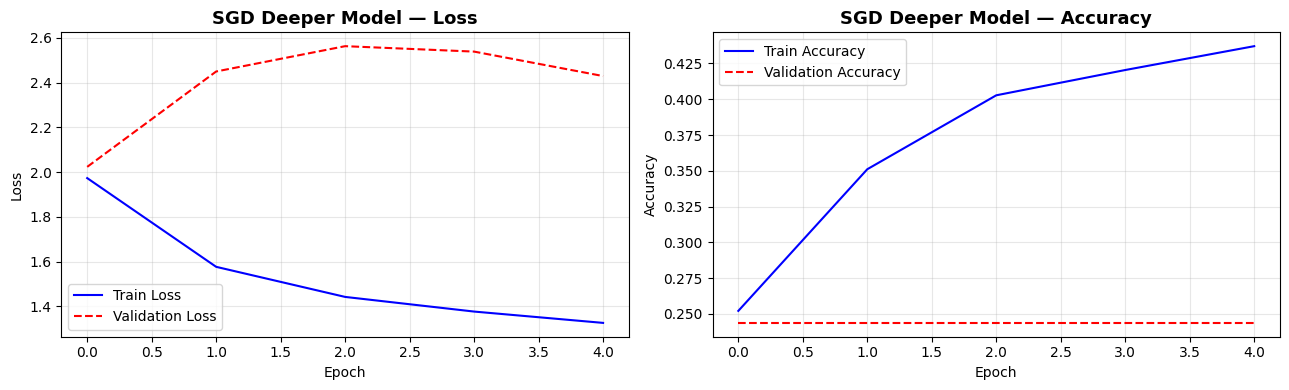

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss
axes[0].plot(history_sgd.history['loss'],     label='Train Loss',      color='blue')
axes[0].plot(history_sgd.history['val_loss'], label='Validation Loss', color='red', linestyle='--')
axes[0].set_title('SGD Deeper Model — Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history_sgd.history['accuracy'],     label='Train Accuracy',      color='blue')
axes[1].plot(history_sgd.history['val_accuracy'], label='Validation Accuracy', color='red', linestyle='--')
axes[1].set_title('SGD Deeper Model — Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("deeper_training_curves.png", dpi=150, bbox_inches='tight')
plt.show()


##Compare Performance of Adam vs SGD - Training Curves

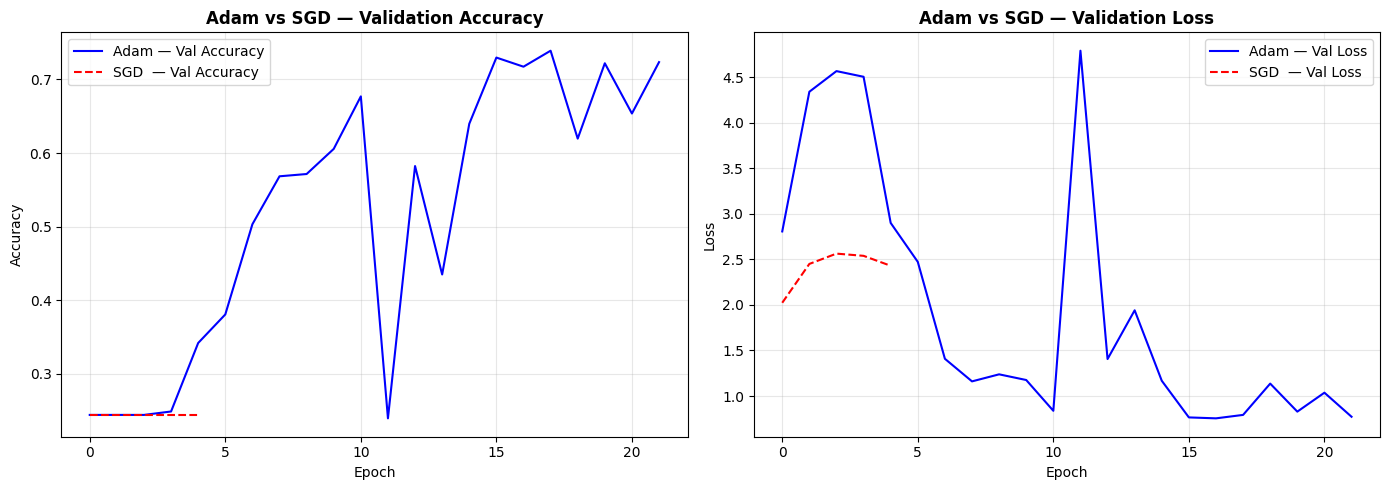

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Accuracy ──
axes[0].plot(history_adam.history['val_accuracy'],
             label='Adam — Val Accuracy', color='blue')
axes[0].plot(history_sgd.history['val_accuracy'],
             label='SGD  — Val Accuracy', color='red', linestyle='--')
axes[0].set_title('Adam vs SGD — Validation Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# ── Loss ──
axes[1].plot(history_adam.history['val_loss'],
             label='Adam — Val Loss', color='blue')
axes[1].plot(history_sgd.history['val_loss'],
             label='SGD  — Val Loss', color='red', linestyle='--')
axes[1].set_title('Adam vs SGD — Validation Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("adam_vs_sgd.png", dpi=150, bbox_inches='tight')
plt.show()


##Evaluate both optimizer on Test Set

In [63]:


loss_adam, acc_adam = model_adam.evaluate(test_generator, verbose=0)
loss_sgd,  acc_sgd  = model_sgd.evaluate(test_generator,  verbose=0)

print("=" * 50)
print(f"{'Metric':<20} {'Adam':>12} {'SGD':>12}")
print("=" * 50)
print(f"{'Test Accuracy':<20} {acc_adam*100:>11.2f}% {acc_sgd*100:>11.2f}%")
print(f"{'Test Loss':<20} {loss_adam:>12.4f} {loss_sgd:>12.4f}")
print(f"{'Training Time (s)':<20} {time_adam:>12.2f} {time_sgd:>12.2f}")
print("=" * 50)

Metric                       Adam          SGD
Test Accuracy              70.90%       24.30%
Test Loss                  0.7430       2.0262
Training Time (s)          690.29       171.90


#Model with the Regularization

In [64]:
from tensorflow.keras.regularizers import l2

REG = l2(0.001)  # define once, reuse everywhere

def build_regularized_deeper_model(optimizer):
    model = Sequential([

        # ── Conv Block 1 ──
        Conv2D(32, (3, 3), padding='same', input_shape=(128, 128, 3),
               kernel_regularizer=REG),          # <-- added
        BatchNormalization(),
        Activation('relu'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # ── Conv Block 2 ──
        Conv2D(64, (3, 3), padding='same',
               kernel_regularizer=REG),
        BatchNormalization(),
        Activation('relu'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),


            # ── Conv Block 3 ── (128 filters)
            Conv2D(128, (3, 3), padding='same',
               kernel_regularizer=REG),
            BatchNormalization(),
            Activation('relu'),
            MaxPooling2D((2, 2)),
            Dropout(0.25),

            # ── Conv Block 4 ── (256 filters)
            Conv2D(256, (3, 3), padding='same',
               kernel_regularizer=REG),
            BatchNormalization(),
            Activation('relu'),
            MaxPooling2D((2, 2)),
            Dropout(0.25),

            # ── Conv Block 5 ── (512 filters)
            Conv2D(512, (3, 3), padding='same',
               kernel_regularizer=REG),
            BatchNormalization(),
            Activation('relu'),
            MaxPooling2D((2, 2)),
            Dropout(0.25),

            # ── Conv Block 6 ── (512 filters)
            Conv2D(512, (3, 3), padding='same',
               kernel_regularizer=REG),
            BatchNormalization(),
            Activation('relu'),
            Dropout(0.25),




        Flatten(),

        # ── Dense Layers ──
        Dense(512, kernel_regularizer=REG),      # <-- added
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.5),

        Dense(256, kernel_regularizer=REG),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.5),

        Dense(128, kernel_regularizer=REG),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.5),

        Dense(NUM_CLASSES, activation='softmax') # no regularizer on output
    ])

    model.compile(
            optimizer=optimizer,
            loss='categorical_crossentropy',
            metrics=['accuracy']
    )
    return model

In [65]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import time

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)


model_reg = build_regularized_deeper_model(optimizer=Adam(learning_rate=0.001))

print("Training Deeper Model with Regularizatioin|...")
start_reg = time.time()

history_reg = model_reg.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator,
    callbacks=[early_stopping]
)

time_reg = time.time() - start_reg
print(f"\n Reg model Training Time: {time_reg:.2f} seconds")

Training Deeper Model with Regularizatioin|...
Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 64s 482ms/step - accuracy: 0.2668 - loss: 4.6979 - val_accuracy: 0.2438 - val_loss: 4.9231
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 316ms/step - accuracy: 0.3884 - loss: 4.1361 - val_accuracy: 0.2438 - val_loss: 6.2327
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 316ms/step - accuracy: 0.4650 - loss: 3.6865 - val_accuracy: 0.2531 - val_loss: 5.6767
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 312ms/step - accuracy: 0.5276 - loss: 3.2850 - val_accuracy: 0.2484 - val_loss: 6.0027
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 313ms/step - accuracy: 0.5603 - loss: 2.9063 - val_accuracy: 0.3447 - val_loss: 3.5397
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 314ms/step - accuracy: 0.5759 - loss: 2.5826 - val_accuracy: 0.2904 - val_loss: 4.3234
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 320ms/step - accuracy: 0.5953 - loss: 2.3189 - val_accuracy: 0.3323 - val_loss: 3.5160
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 317ms/st

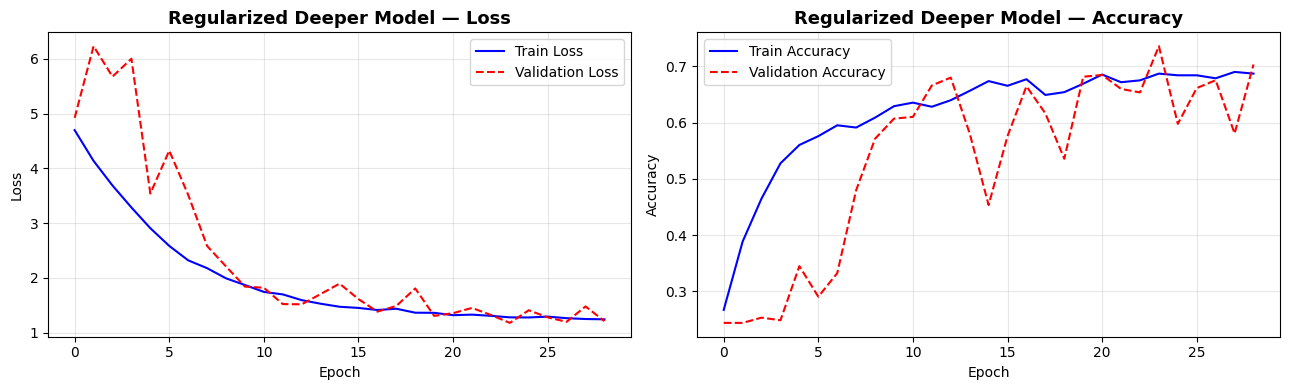

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss
axes[0].plot(history_reg.history['loss'],     label='Train Loss',      color='blue')
axes[0].plot(history_reg.history['val_loss'], label='Validation Loss', color='red', linestyle='--')
axes[0].set_title('Regularized Deeper Model — Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history_reg.history['accuracy'],     label='Train Accuracy',      color='blue')
axes[1].plot(history_reg.history['val_accuracy'], label='Validation Accuracy', color='red', linestyle='--')
axes[1].set_title('Regularized Deeper Model — Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("deeper_training_curves.png", dpi=150, bbox_inches='tight')
plt.show()


In [67]:
test_loss, test_accuracy = model_reg.evaluate(test_generator)

print("\n" + "=" * 40)
print(f"  Regularized Deeper Model — Test Results")
print("=" * 40)
print(f"  Test Loss     : {test_loss:.4f}")
print(f"  Test Accuracy : {test_accuracy * 100:.2f}%")
print("=" * 40)

21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 203ms/step - accuracy: 0.7090 - loss: 1.1627

  Regularized Deeper Model — Test Results
  Test Loss     : 1.1627
  Test Accuracy : 70.90%


#Comparision between Baseline vs Deeper Model(Adam)

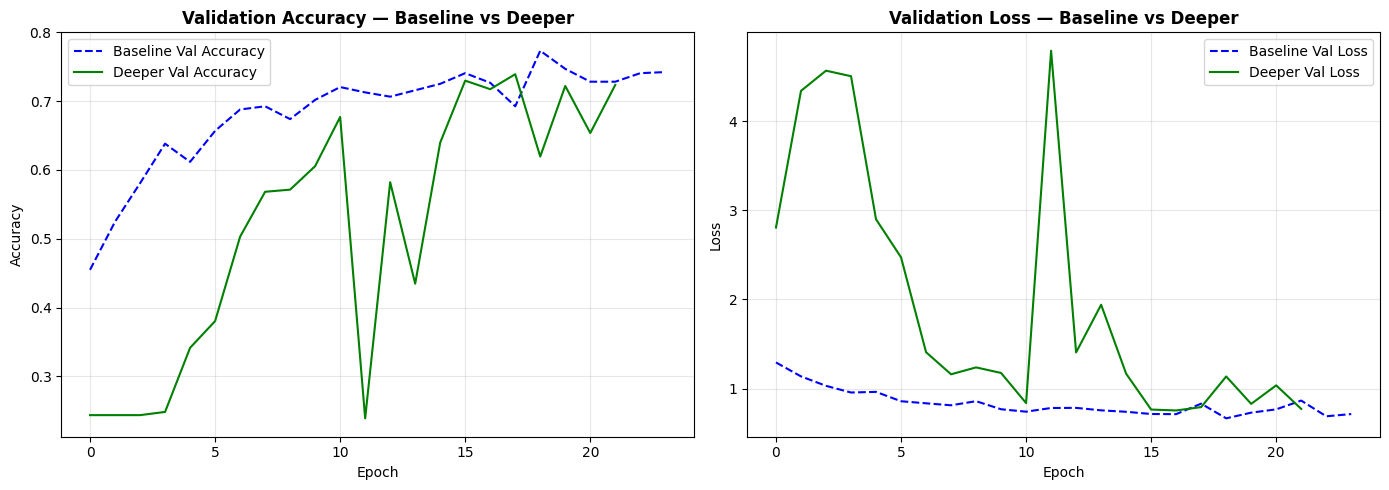

In [69]:
# ── Load baseline history (must have run Stage 2 first) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Accuracy Comparison ──
axes[0].plot(baseline_history.history['val_accuracy'],
             label='Baseline Val Accuracy', color='blue', linestyle='--')
axes[0].plot(history_adam.history['val_accuracy'],
             label='Deeper Val Accuracy',   color='green')
axes[0].set_title('Validation Accuracy — Baseline vs Deeper', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# ── Loss Comparison ──
axes[1].plot(baseline_history.history['val_loss'],
             label='Baseline Val Loss', color='blue', linestyle='--')
axes[1].plot(history_adam.history['val_loss'],
             label='Deeper Val Loss',   color='green')
axes[1].set_title('Validation Loss — Baseline vs Deeper', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("baseline_vs_deeper.png", dpi=150, bbox_inches='tight')
plt.show()


In [68]:
# ── Get baseline results vs Deeper results ──
baseline_test_loss, baseline_test_acc = baseline_model.evaluate(test_generator, verbose=0)
loss_adam,   acc_adam   = model_adam.evaluate(test_generator,   verbose=0)

print("=" * 55)
print(f"{'Metric':<25} {'Baseline':>12} {'Deeper':>12}")
print("=" * 55)
print(f"{'Test Accuracy':<25} {baseline_test_acc*100:>11.2f}% {acc_adam*100:>11.2f}%")
print(f"{'Test Loss':<25} {baseline_test_loss:>12.4f} {loss_adam:>12.4f}")
print(f"{'Training Time (s)':<25} {baseline_training_time:>12.2f} {time_adam:>12.2f}")



Metric                        Baseline       Deeper
Test Accuracy                   75.70%       70.90%
Test Loss                       0.6748       0.7430
Training Time (s)               719.26       690.29


#Ablation Study - Remove Dropout

As we can see, without dropout the model starts overfitting as compare to previous deepr model t which results that this regularization method plays a crucial role for reducing the problem of overfitting.

In [ ]:
# ── Model WITHOUT Dropout ──
model_no_dropout = Sequential([

    Conv2D(32, (3, 3), padding='same', input_shape=(128, 128, 3)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),

    Conv2D(256, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),

    Conv2D(512, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),

    Conv2D(512, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),

    Flatten(),

    Dense(512),
    BatchNormalization(),
    Activation('relu'),

    Dense(256),
    BatchNormalization(),
    Activation('relu'),

    Dense(128),
    BatchNormalization(),
    Activation('relu'),

    Dense(NUM_CLASSES, activation='softmax')
])

#Compile the model

model_no_dropout.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Training model WITHOUT Dropout...")
start_ablation = time.time()

history_no_dropout = model_no_dropout.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator,
    callbacks=[early_stopping]
)

time_ablation = time.time() - start_ablation
print(f"\nAblation Training Time: {time_ablation:.2f} seconds")

Training model WITHOUT Dropout...
Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 48s 382ms/step - accuracy: 0.5319 - loss: 1.1608 - val_accuracy: 0.2420 - val_loss: 4.4825
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 312ms/step - accuracy: 0.5979 - loss: 0.9923 - val_accuracy: 0.2573 - val_loss: 4.4141
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 322ms/step - accuracy: 0.6183 - loss: 0.9675 - val_accuracy: 0.2726 - val_loss: 3.5722
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 317ms/step - accuracy: 0.6567 - loss: 0.8848 - val_accuracy: 0.4717 - val_loss: 1.4103
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 318ms/step - accuracy: 0.6810 - loss: 0.8375 - val_accuracy: 0.5850 - val_loss: 1.2572
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 316ms/step - accuracy: 0.6859 - loss: 0.8397 - val_accuracy: 0.6447 - val_loss: 0.9818
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 312ms/step - accuracy: 0.6892 - loss: 0.7830 - val_accuracy: 0.5865 - val_loss: 1.2219
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 315ms/step - accuracy

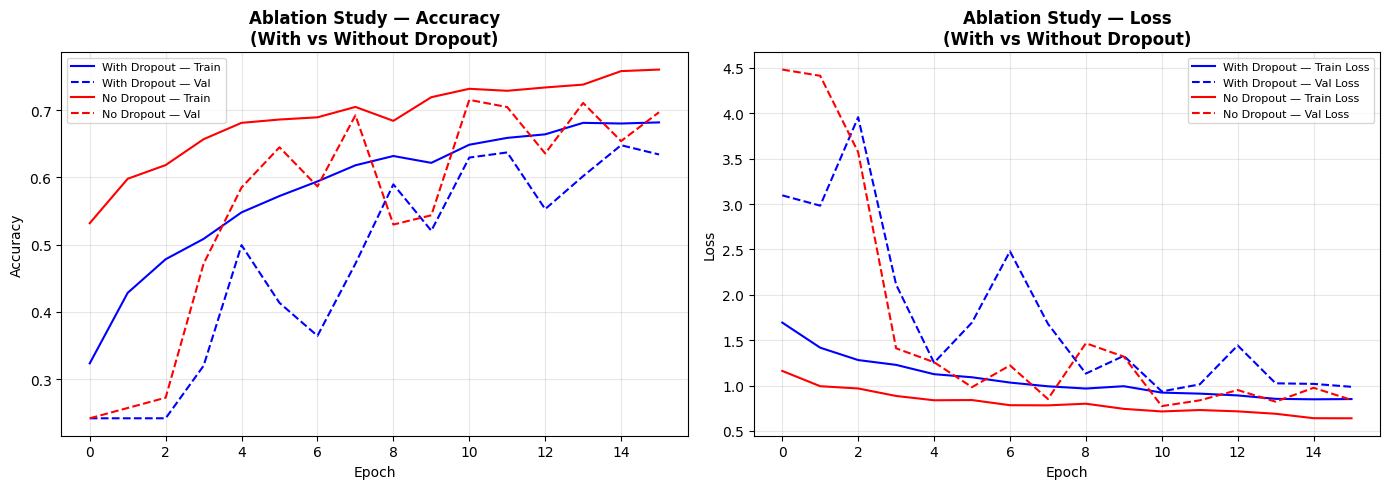

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Accuracy ──
axes[0].plot(history_adam.history['train_accuracy'] if 'train_accuracy' in history_adam.history else history_adam.history['accuracy'],
             label='With Dropout — Train', color='blue')
axes[0].plot(history_adam.history['val_accuracy'],
             label='With Dropout — Val', color='blue', linestyle='--')
axes[0].plot(history_no_dropout.history['accuracy'],
             label='No Dropout — Train', color='red')
axes[0].plot(history_no_dropout.history['val_accuracy'],
             label='No Dropout — Val', color='red', linestyle='--')
axes[0].set_title('Ablation Study — Accuracy\n(With vs Without Dropout)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# ── Loss ──
axes[1].plot(history_adam.history['loss'],
             label='With Dropout — Train Loss', color='blue')
axes[1].plot(history_adam.history['val_loss'],
             label='With Dropout — Val Loss', color='blue', linestyle='--')
axes[1].plot(history_no_dropout.history['loss'],
             label='No Dropout — Train Loss', color='red')
axes[1].plot(history_no_dropout.history['val_loss'],
             label='No Dropout — Val Loss', color='red', linestyle='--')
axes[1].set_title('Ablation Study — Loss\n(With vs Without Dropout)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("ablation_study.png", dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# Evaluate all models on test set
test_generator.reset()
loss_baseline, acc_baseline     = baseline_model.evaluate(test_generator, verbose=0)
test_generator.reset()
loss_adam, acc_adam             = model_adam.evaluate(test_generator, verbose=0)
test_generator.reset()
loss_sgd, acc_sgd               = model_sgd.evaluate(test_generator, verbose=0)
test_generator.reset()
loss_no_drop, acc_no_drop       = model_no_dropout.evaluate(test_generator, verbose=0)

print("=" * 70)
print(f"{'Model':<25} {'Test Acc':>10} {'Test Loss':>12} {'Train Time(s)':>15}")
print("=" * 70)
print(f"{'Baseline CNN':<25} {acc_baseline*100:>9.2f}% {loss_baseline:>12.4f} {baseline_training_time:>15.2f}")
print(f"{'Deeper + Adam':<25} {acc_adam*100:>9.2f}% {loss_adam:>12.4f} {time_adam:>15.2f}")
print(f"{'Deeper + SGD':<25} {acc_sgd*100:>9.2f}% {loss_sgd:>12.4f} {time_sgd:>15.2f}")
print(f"{'Deeper (No Dropout)':<25} {acc_no_drop*100:>9.2f}% {loss_no_drop:>12.4f} {time_ablation:>15.2f}")
print("=" * 70)

Model                       Test Acc    Test Loss   Train Time(s)
Baseline CNN                  74.62%       0.7913          933.75
Deeper + Adam                 62.39%       1.0038          513.60
Deeper + SGD                  24.16%       1.7192          177.01
Deeper (No Dropout)           71.87%       0.8502          504.14


##Classification Report

In [ ]:
test_generator.reset()
predictions      = model_adam.predict(test_generator)
predicted_labels = np.argmax(predictions, axis=1)
true_labels      = test_generator.classes
class_names      = list(test_generator.class_indices.keys())

print("Classification Report — Deeper Model (Adam):")
print("=" * 60)
print(classification_report(true_labels, predicted_labels,
                             target_names=class_names))

21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 171ms/step
Classification Report — Deeper Model (Adam):
              precision    recall  f1-score   support

       daisy       0.89      0.57      0.70       117
   dandelion       0.52      0.94      0.67       158
        rose       0.58      0.18      0.28       120
   sunflower       0.85      0.59      0.70       111
       tulip       0.59      0.71      0.64       148

    accuracy                           0.62       654
   macro avg       0.69      0.60      0.60       654
weighted avg       0.67      0.62      0.60       654



##Confusion Matrix

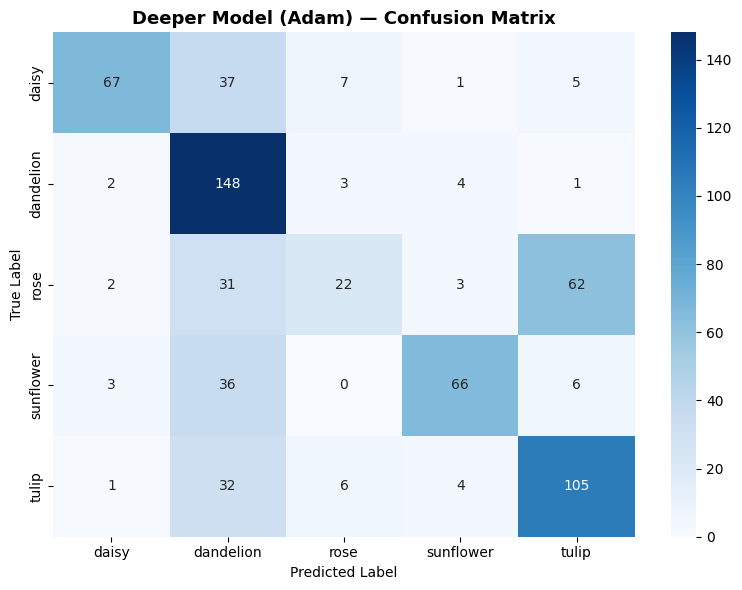

In [ ]:
cm = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Deeper Model (Adam) — Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig("deeper_confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()


**Key Obverations overall:**

####-Deeper model take longer time to train as compare to baseline due to the more layers.
####-Adam train better than the SGD
####-Model without dropout shows higher train acc but lower val acc
####-Dropout have significant role to reduce the overfitting


In [ ]:
model_adam.save("deeper_model_adam.h5")
model_sgd.save("deeper_model_sgd.h5")
print("Both models saved successfully!")

Both models saved successfully!


# Part B: Fine-Tuning a Pre-Trained Model (Transfer Learning)

In [ ]:
IMG_SIZE   = (224, 224) # Changed to (224, 224) for VGG16 input requirements
BATCH_SIZE = 32
NUM_CLASSES = 5

In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os # Added import os for directory checks

# Check if train_dir exists. If not, prompt the user to run the data splitting cell.
if not os.path.exists(train_dir):
    print(f"Error: The directory '{train_dir}' was not found. Please ensure you have run cell 'f_WJqaiG1cx1' to perform the data splitting before executing this cell.")
    raise FileNotFoundError(f"Directory not found: {train_dir}. Please run data splitting cell 'f_WJqaiG1cx1'.")

# ── Training Generator: Augmentation + VGG16 Preprocessing ──
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # VGG16 specific normalization
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# ── Val & Test: VGG16 Preprocessing ONLY ──
val_datagen  = ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"\nClass indices : {train_generator.class_indices}")
print(f"   Train batches : {len(train_generator)}")
print(f"   Val   batches : {len(val_generator)}")
print(f"   Test  batches : {len(test_generator)}")

Found 3044 images belonging to 5 classes.
Found 653 images belonging to 5 classes.
Found 654 images belonging to 5 classes.

Class indices : {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}
   Train batches : 96
   Val   batches : 21
   Test  batches : 21


##Load VGG16 Pre-Trained Model



In [ ]:
from tensorflow.keras.applications.vgg16 import VGG16
# Load VGG16 without the top classification layer
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

print(" VGG16 loaded successfully!")
print(f"   Total layers in VGG16: {len(base_model.layers)}")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
 VGG16 loaded successfully!
   Total layers in VGG16: 19


##Freeze All Base Layers - Feature Extraction

In [ ]:
# Freeze ALL layers of VGG16
for layer in base_model.layers:
    layer.trainable = False

# Verify frozen layers
print(f"Total layers     : {len(base_model.layers)}")
print(f"Trainable layers : {sum(1 for l in base_model.layers if l.trainable)}")
print(f"Frozen layers    : {sum(1 for l in base_model.layers if not l.trainable)}")

Total layers     : 19
Trainable layers : 0
Frozen layers    : 19


##Add the Custom layers for Flower Classification

In [ ]:
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Add custom layers on top of VGG16
x = base_model.output
x = GlobalAveragePooling2D()(x)          # Reduce spatial dimensions
x = Dense(256, activation='relu')(x)     # Fully connected layer
x = Dropout(0.5)(x)                      # Regularization
output = Dense(NUM_CLASSES, activation='softmax')(x)  # 5 flower classes

# Create the final model
model_tl = Model(inputs=base_model.input, outputs=output)

print("Custom model created!")
print(f"   Total layers     : {len(model_tl.layers)}")
print(f"   Trainable layers : {sum(1 for l in model_tl.layers if l.trainable)}")
print(f"   Frozen layers    : {sum(1 for l in model_tl.layers if not l.trainable)}")

Custom model created!
   Total layers     : 23
   Trainable layers : 4
   Frozen layers    : 19


In [ ]:
model_tl.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

##Compile and Train - 1. Feature Extraction

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import time

# Compile
model_tl.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("Training Strategy 1: Feature Extraction...")
start_fe = time.time()

history_fe = model_tl.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    callbacks=[early_stopping]
)

time_fe = time.time() - start_fe
print(f"\n Feature Extraction Training Time: {time_fe:.2f} seconds")

Training Strategy 1: Feature Extraction...
Epoch 1/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 84s 708ms/step - accuracy: 0.6317 - loss: 1.6517 - val_accuracy: 0.8178 - val_loss: 0.5645
Epoch 2/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 601ms/step - accuracy: 0.7717 - loss: 0.6567 - val_accuracy: 0.8484 - val_loss: 0.4319
Epoch 3/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 83s 607ms/step - accuracy: 0.7963 - loss: 0.5681 - val_accuracy: 0.8591 - val_loss: 0.4377
Epoch 4/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 59s 608ms/step - accuracy: 0.8150 - loss: 0.4964 - val_accuracy: 0.8668 - val_loss: 0.4241
Epoch 5/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 59s 617ms/step - accuracy: 0.8295 - loss: 0.4474 - val_accuracy: 0.8775 - val_loss: 0.3950
Epoch 6/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 59s 615ms/step - accuracy: 0.8397 - loss: 0.4387 - val_accuracy: 0.8821 - val_loss: 0.3601
Epoch 7/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 606ms/step - accuracy: 0.8525 - loss: 0.3931 - val_accuracy: 0.8821 - val_loss: 0.3687
Epoch 8/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 608ms/step -

##Plot Training Curves - Feature Extraction

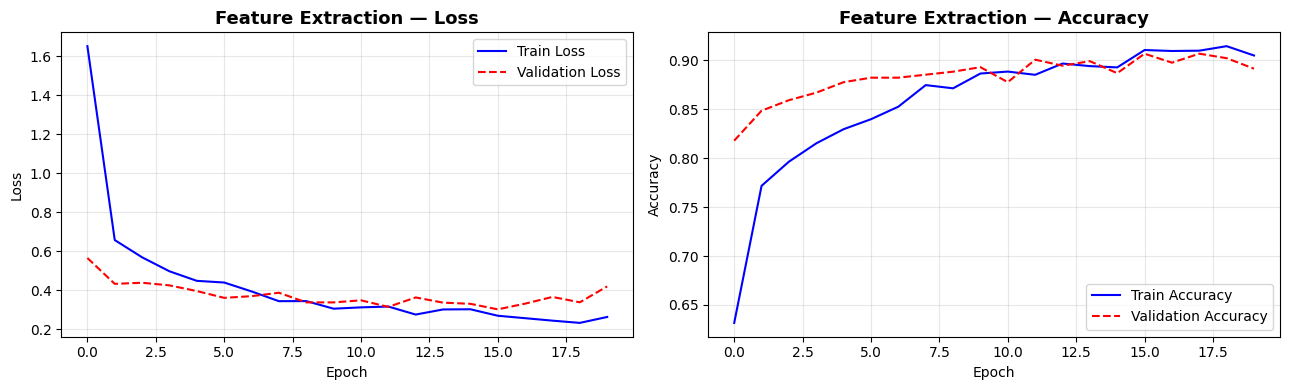

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_fe.history['loss'],     label='Train Loss',      color='blue')
axes[0].plot(history_fe.history['val_loss'], label='Validation Loss', color='red', linestyle='--')
axes[0].set_title('Feature Extraction — Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_fe.history['accuracy'],     label='Train Accuracy',      color='blue')
axes[1].plot(history_fe.history['val_accuracy'], label='Validation Accuracy', color='red', linestyle='--')
axes[1].set_title('Feature Extraction — Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("feature_extraction_curves.png", dpi=150, bbox_inches='tight')
plt.show()

##Evaluate - Feature Extraction

In [ ]:
loss_tl, acc_tl = model_tl.evaluate(test_generator, verbose=0)

print("\n" + "=" * 45)
print("  Strategy 1: Feature Extraction Results")
print("=" * 45)
print(f"  Test Loss     : {loss_tl:.4f}")
print(f"  Test Accuracy : {acc_tl * 100:.2f}%")
print("=" * 45)


  Strategy 1: Feature Extraction Results
  Test Loss     : 0.3661
  Test Accuracy : 90.37%


##2. Fine Tuning

In [ ]:
for layer in model_tl.layers:
    layer.trainable = False       # freeze all first

for layer in model_tl.layers[-4:]:
    layer.trainable = True

# Verify
print(f"Total layers     : {len(model_tl.layers)}")
print(f"Trainable layers : {sum(1 for l in model_tl.layers if l.trainable)}")
print(f"Frozen layers    : {sum(1 for l in model_tl.layers if not l.trainable)}")

# Print which layers are trainable
print("\nTrainable layer names:")
for layer in model_tl.layers:
    if layer.trainable:
        print(f" {layer.name}")

Total layers     : 23
Trainable layers : 4
Frozen layers    : 19

Trainable layer names:
 global_average_pooling2d
 dense_24
 dropout_36
 dense_25


In [ ]:
# Recompile with VERY LOW learning rate
model_tl.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping_ft = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("Training Strategy 2: Fine Tuning...")
start_ft = time.time()

history_ft = model_tl.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    callbacks=[early_stopping_ft]
)

time_ft = time.time() - start_ft
print(f"\n Fine Tuning Training Time: {time_ft:.2f} seconds")

Training Strategy 2: Fine Tuning...
Epoch 1/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 643ms/step - accuracy: 0.9343 - loss: 0.1916 - val_accuracy: 0.9035 - val_loss: 0.3634
Epoch 2/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 59s 619ms/step - accuracy: 0.9297 - loss: 0.1942 - val_accuracy: 0.9051 - val_loss: 0.3648
Epoch 3/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 60s 620ms/step - accuracy: 0.9379 - loss: 0.1822 - val_accuracy: 0.9051 - val_loss: 0.3722
Epoch 4/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 603ms/step - accuracy: 0.9340 - loss: 0.1760 - val_accuracy: 0.9081 - val_loss: 0.3744
Epoch 5/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 600ms/step - accuracy: 0.9294 - loss: 0.1955 - val_accuracy: 0.9081 - val_loss: 0.3634
Epoch 6/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 602ms/step - accuracy: 0.9333 - loss: 0.1805 - val_accuracy: 0.9066 - val_loss: 0.3614
Epoch 7/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 605ms/step - accuracy: 0.9297 - loss: 0.1899 - val_accuracy: 0.9081 - val_loss: 0.3626
Epoch 8/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 601ms/step - accura

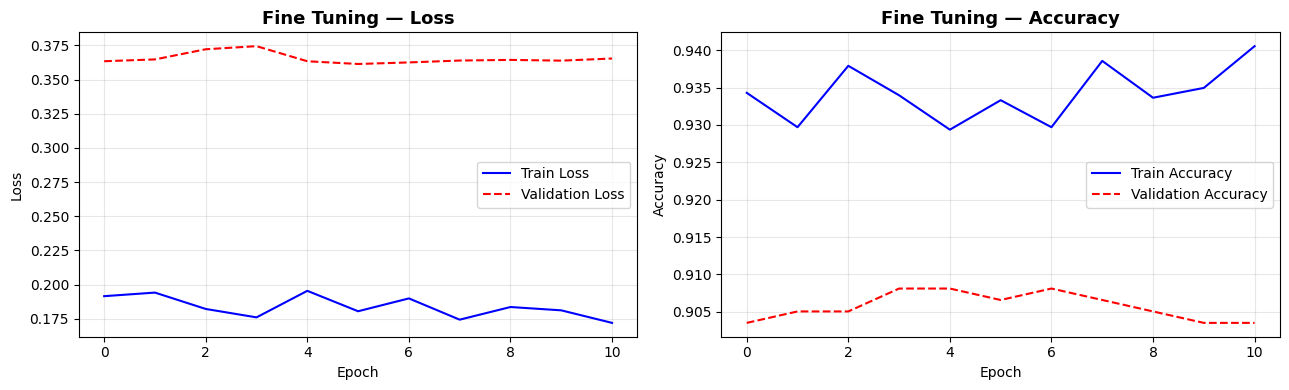

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_ft.history['loss'],     label='Train Loss',      color='blue')
axes[0].plot(history_ft.history['val_loss'], label='Validation Loss', color='red', linestyle='--')
axes[0].set_title('Fine Tuning — Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_ft.history['accuracy'],     label='Train Accuracy',      color='blue')
axes[1].plot(history_ft.history['val_accuracy'], label='Validation Accuracy', color='red', linestyle='--')
axes[1].set_title('Fine Tuning — Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fine_tuning_curves.png", dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
loss_ft, acc_ft = model_tl.evaluate(test_generator, verbose=0)

print("\n" + "=" * 45)
print("  Strategy 2: Fine Tuning Results")
print("=" * 45)
print(f"  Test Loss     : {loss_ft:.4f}")
print(f"  Test Accuracy : {acc_ft * 100:.2f}%")
print("=" * 45)


  Strategy 2: Fine Tuning Results
  Test Loss     : 0.3921
  Test Accuracy : 89.76%


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

# Reset before predicting
test_generator.reset()

predictions      = model_tl.predict(test_generator)
predicted_labels = np.argmax(predictions, axis=1)
true_labels      = test_generator.classes
class_names      = list(test_generator.class_indices.keys())

print(f"Predictions : {len(predicted_labels)}")
print(f"True labels : {len(true_labels)}")

print("\nClassification Report:")
print("=" * 60)
print(classification_report(true_labels, predicted_labels,
                             target_names=class_names))

21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step
Predictions : 654
True labels : 654

Classification Report:
              precision    recall  f1-score   support

       daisy       0.90      0.91      0.90       117
   dandelion       0.91      0.93      0.92       158
        rose       0.88      0.93      0.90       120
   sunflower       0.93      0.82      0.87       111
       tulip       0.88      0.89      0.89       148

    accuracy                           0.90       654
   macro avg       0.90      0.89      0.90       654
weighted avg       0.90      0.90      0.90       654



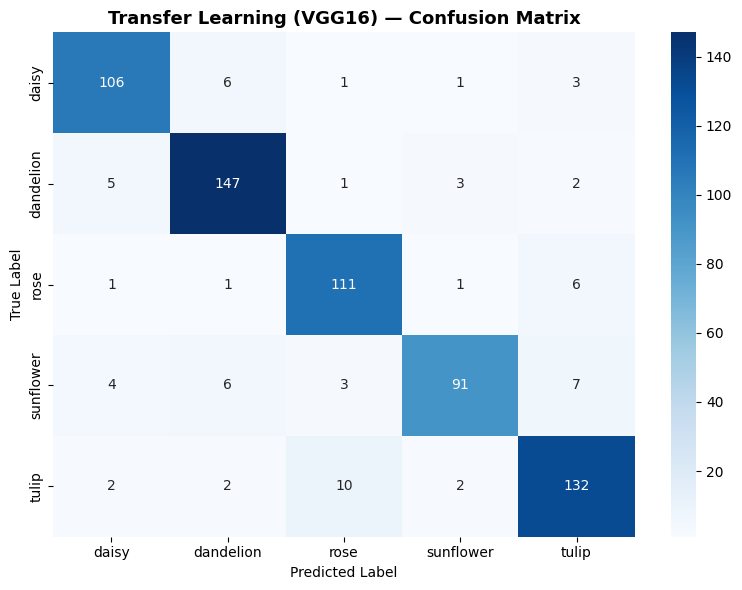

 Confusion matrix saved.


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Transfer Learning (VGG16) — Confusion Matrix',
          fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig("transfer_learning_confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()
print(" Confusion matrix saved.")